# 1. Title and experiment scope

# MANNeR Reproduction on MINDsmall
**Course:** CP8339 Recommender Systems
**Experiment:** MANNeR category-customization reproduction
**Dataset:** MINDsmall
**Models:** CR-Module and Category A-Module
**Input:** News titles
**Pretrained language model:** roberta-base
**Random seed:** 42

# Scope
This notebook reproduces a bounded MANNeR experiment using:

1. CR-Module for relevance-based news recommendation.
2. Category A-Module for category representation.
3. Category-only MANNeR ensemble evaluation.

The experiment excludes sentiment customization, multilingual transfer, MINDlarge, baseline reproduction, ablation studies, and hyperparameter optimization.

# 2. Runtime and GPU verification

In [1]:
import sys
import platform
import torch

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA runtime:", torch.version.cuda)

if not torch.cuda.is_available():
    raise RuntimeError(
        "A GPU runtime is required. Select Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

test_tensor = torch.randn(1000, 1000, device="cuda")
test_result = test_tensor @ test_tensor

print("GPU tensor test:", test_result.shape)
print("GPU verification passed.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cu130
CUDA available: True
CUDA runtime: 13.0
GPU: Tesla T4
GPU tensor test: torch.Size([1000, 1000])
GPU verification passed.


# 3. Mount Google Drive and define paths

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CP8339_Assignment2_MANNeR"
)

REPO_DIR = Path("/content/manner")
DATA_DIR = PROJECT_DIR / "data"
CONFIG_DIR = PROJECT_DIR / "configs_used"
LOG_DIR = PROJECT_DIR / "logs"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
RUNS_DIR = PROJECT_DIR / "runs"
PATCH_DIR = PROJECT_DIR / "code_changes"

for directory in [
    DATA_DIR,
    CONFIG_DIR,
    LOG_DIR,
    CHECKPOINT_DIR,
    RESULTS_DIR,
    RUNS_DIR,
    PATCH_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())

Project directory: /content/drive/MyDrive/CP8339_Assignment2_MANNeR
Project exists: True


# 4. Clone the pinned MANNeR repository

In [4]:
import subprocess

EXPECTED_COMMIT = (
    "a831482f4d9b4918cb7625aed1c66bb68b6db1fe"
)

if not REPO_DIR.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/andreeaiana/manner.git",
            str(REPO_DIR),
        ],
        check=True,
    )

active_commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()

if active_commit != EXPECTED_COMMIT:
    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "checkout",
            EXPECTED_COMMIT,
        ],
        check=True,
    )

active_commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()

print("Active MANNeR commit:", active_commit)

assert active_commit == EXPECTED_COMMIT

Active MANNeR commit: a831482f4d9b4918cb7625aed1c66bb68b6db1fe


Create the project-root marker:

In [5]:
PROJECT_ROOT_MARKER = REPO_DIR / ".project-root"
PROJECT_ROOT_MARKER.touch(exist_ok=True)

print("Project-root marker:", PROJECT_ROOT_MARKER)

Project-root marker: /content/manner/.project-root


# 5. Install the reproducible dependency environment

Use one installation cell with real < and > characters:

In [7]:
%cd /content/manner

!python -m pip install -q \
    "lightning>=2.0,<3" \
    "torchmetrics>=0.11.4,<2" \
    "hydra-core==1.3.2" \
    "hydra-colorlog==1.2.0" \
    "pytorch-metric-learning>=2.1.1,<3" \
    "transformers>=4.29.2,<5" \
    "sentencepiece>=0.1.99" \
    "pyrootutils>=1.0.4" \
    "retrying>=1.3.4" \
    "rich>=13" \
    "colorcet>=3.0.1" \
    "wandb>=0.15" \
    "torch-geometric>=2.3.1"

print("Dependency installation completed.")

/content/manner
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Dependency installation completed.


After running the dependency-installation cell in a fresh runtime, restart the Colab session. Then rerun the GPU, Drive, path, repository, and verification cells. Do not reinstall the dependencies again unless the import verification fails.

0. Restart the session
1. Runtime and GPU verification
2. Mount Google Drive and define paths
3. Clone or verify the pinned MANNeR repository
4. Create the .project-root marker

not 5. installation and move on to the next

6. Dependency import verification

# 6. Verify dependencies

In [6]:
import importlib
import importlib.metadata as metadata

packages = {
    "lightning": "lightning",
    "torchmetrics": "torchmetrics",
    "transformers": "transformers",
    "huggingface-hub": "huggingface_hub",
    "hydra-core": "hydra",
    "omegaconf": "omegaconf",
    "pytorch-metric-learning": "pytorch_metric_learning",
    "torch-geometric": "torch_geometric",
    "pyrootutils": "pyrootutils",
    "sentencepiece": "sentencepiece",
    "retrying": "retrying",
    "rich": "rich",
    "colorcet": "colorcet",
    "wandb": "wandb",
}

failed = []

for package_name, import_name in packages.items():
    try:
        module = importlib.import_module(import_name)

        try:
            version = metadata.version(package_name)
        except Exception:
            version = getattr(
                module,
                "__version__",
                "version unavailable",
            )

        print(f"[OK] {package_name:28s} {version}")

    except Exception as error:
        failed.append(package_name)
        print(
            f"[FAILED] {package_name:28s} "
            f"{type(error).__name__}: {error}"
        )

if failed:
    raise RuntimeError(
        "Missing dependencies: " + ", ".join(failed)
    )

print("\nAll required dependencies passed.")

[OK] lightning                    2.6.6
[OK] torchmetrics                 1.9.0
[OK] transformers                 4.57.6
[OK] huggingface-hub              0.36.2
[OK] hydra-core                   1.3.2
[OK] omegaconf                    2.3.1
[OK] pytorch-metric-learning      2.9.0


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[OK] torch-geometric              2.8.1
[OK] pyrootutils                  1.0.4
[OK] sentencepiece                0.2.2
[OK] retrying                     1.4.2
[OK] rich                         13.9.4
[OK] colorcet                     3.2.1
[OK] wandb                        0.28.1

All required dependencies passed.


# 7. Apply compatibility adjustments in one cell

In [8]:
from pathlib import Path
import re
import shutil

# Ensure pyrootutils can identify the repository.
(REPO_DIR / ".project-root").touch(exist_ok=True)

# ------------------------------------------------------------------
# Patch 1: MulticoreTSNE fallback for the Category A-Module.
# ------------------------------------------------------------------

A_MODULE_PATH = REPO_DIR / "manner/models/a_module.py"

a_source = A_MODULE_PATH.read_text(encoding="utf-8")

original_tsne_import = (
    "from MulticoreTSNE import MulticoreTSNE as TSNE"
)

robust_tsne_import = """try:
    from MulticoreTSNE import MulticoreTSNE as TSNE
except ModuleNotFoundError:
    from sklearn.manifold import TSNE as SklearnTSNE

    def TSNE(n_jobs=None, **kwargs):
        return SklearnTSNE(**kwargs)"""

if original_tsne_import in a_source:
    a_source = a_source.replace(
        original_tsne_import,
        robust_tsne_import,
    )

# Disable optional TSNE validation plots in the reproducible runs.
a_source = a_source.replace(
    "if self.current_epoch % 10 == 0:",
    "if False and self.current_epoch % 10 == 0:",
)

A_MODULE_PATH.write_text(
    a_source,
    encoding="utf-8",
)

# ------------------------------------------------------------------
# Patch 2: TorchMetrics retrieval API.
# ------------------------------------------------------------------

for file_path in (REPO_DIR / "manner").rglob("*.py"):
    source = file_path.read_text(encoding="utf-8")

    patched = re.sub(
        r"(Retrieval[A-Za-z]+\()k=",
        r"\1top_k=",
        source,
    )

    if patched != source:
        file_path.write_text(
            patched,
            encoding="utf-8",
        )

print("Compatibility adjustments applied.")

Compatibility adjustments applied.


Then verify:

In [9]:
CR_MODULE_PATH = REPO_DIR / "manner/models/cr_module.py"
ENSEMBLE_MODULE_PATH = REPO_DIR / "manner/models/ensemble_module.py"

a_source = A_MODULE_PATH.read_text(encoding="utf-8")
cr_source = CR_MODULE_PATH.read_text(encoding="utf-8")
ensemble_source = ENSEMBLE_MODULE_PATH.read_text(encoding="utf-8")

assert "from sklearn.manifold import TSNE" in a_source
assert "RetrievalNormalizedDCG(k=" not in cr_source
assert "RetrievalNormalizedDCG(top_k=5)" in cr_source
assert "RetrievalNormalizedDCG(k=" not in ensemble_source
assert "RetrievalNormalizedDCG(top_k=5)" in ensemble_source

print("Compatibility-patch verification passed.")

Compatibility-patch verification passed.


# 8. Verify the persistent dataset

In [10]:
required_raw_files = [
    "behaviors.tsv",
    "news.tsv",
    "entity_embedding.vec",
    "relation_embedding.vec",
]

for split_name in [
    "MINDsmall_train",
    "MINDsmall_dev",
]:
    split_dir = DATA_DIR / split_name

    print("\n", split_name)

    if not split_dir.is_dir():
        raise FileNotFoundError(
            f"Dataset directory is missing: {split_dir}"
        )

    for filename in required_raw_files:
        path = split_dir / filename
        valid = path.is_file() and path.stat().st_size > 0

        print(
            "[OK]" if valid else "[MISSING]",
            filename,
            f"{path.stat().st_size:,} bytes" if valid else "",
        )

        if not valid:
            raise RuntimeError(
                f"Missing dataset file: {path}"
            )

print("\nRaw MINDsmall dataset verification passed.")


 MINDsmall_train
[OK] behaviors.tsv 92,019,716 bytes
[OK] news.tsv 41,202,121 bytes
[OK] entity_embedding.vec 25,811,015 bytes
[OK] relation_embedding.vec 1,044,588 bytes

 MINDsmall_dev
[OK] behaviors.tsv 42,838,544 bytes
[OK] news.tsv 33,519,092 bytes
[OK] entity_embedding.vec 21,960,998 bytes
[OK] relation_embedding.vec 1,044,588 bytes

Raw MINDsmall dataset verification passed.


Verify preprocessing:

In [11]:
required_preprocessed_files = [
    DATA_DIR / "MINDsmall_train" / "parsed_news.tsv",
    DATA_DIR / "MINDsmall_train" / "train_parsed_behaviors.tsv",
    DATA_DIR / "MINDsmall_train" / "val_parsed_behaviors.tsv",
    DATA_DIR / "MINDsmall_train" / "uid2index.tsv",
    DATA_DIR / "MINDsmall_train" / "categ2index.tsv",
    DATA_DIR / "MINDsmall_train" / "sentiment2index.tsv",
    DATA_DIR / "MINDsmall_train" / "entity2index.tsv",
    DATA_DIR / "MINDsmall_train" / "entity_embedding.npy",
    DATA_DIR / "MINDsmall_train" / "categ_embedding.npy",
    DATA_DIR / "MINDsmall_dev" / "parsed_news.tsv",
    DATA_DIR / "MINDsmall_dev" / "parsed_behaviors.tsv",
    DATA_DIR / "glove" / "glove.840B.300d.txt",
]

for path in required_preprocessed_files:
    valid = path.is_file() and path.stat().st_size > 0

    print(
        "[OK]" if valid else "[MISSING]",
        path.relative_to(DATA_DIR),
        f"{path.stat().st_size:,} bytes" if valid else "",
    )

    if not valid:
        raise RuntimeError(
            f"Missing preprocessing file: {path}"
        )

print("\nMINDsmall preprocessing cache verification passed.")

[OK] MINDsmall_train/parsed_news.tsv 19,843,601 bytes
[OK] MINDsmall_train/train_parsed_behaviors.tsv 99,551,891 bytes
[OK] MINDsmall_train/val_parsed_behaviors.tsv 25,373,244 bytes
[OK] MINDsmall_train/uid2index.tsv 571,346 bytes
[OK] MINDsmall_train/categ2index.tsv 193 bytes
[OK] MINDsmall_train/sentiment2index.tsv 48 bytes
[OK] MINDsmall_train/entity2index.tsv 123,092 bytes
[OK] MINDsmall_train/entity_embedding.npy 7,394,528 bytes
[OK] MINDsmall_train/categ_embedding.npy 43,328 bytes
[OK] MINDsmall_dev/parsed_news.tsv 16,087,865 bytes
[OK] MINDsmall_dev/parsed_behaviors.tsv 57,649,879 bytes
[OK] glove/glove.840B.300d.txt 5,646,239,124 bytes

MINDsmall preprocessing cache verification passed.


# 9. Experiment configuration summary

## Final CR-Module Configuration

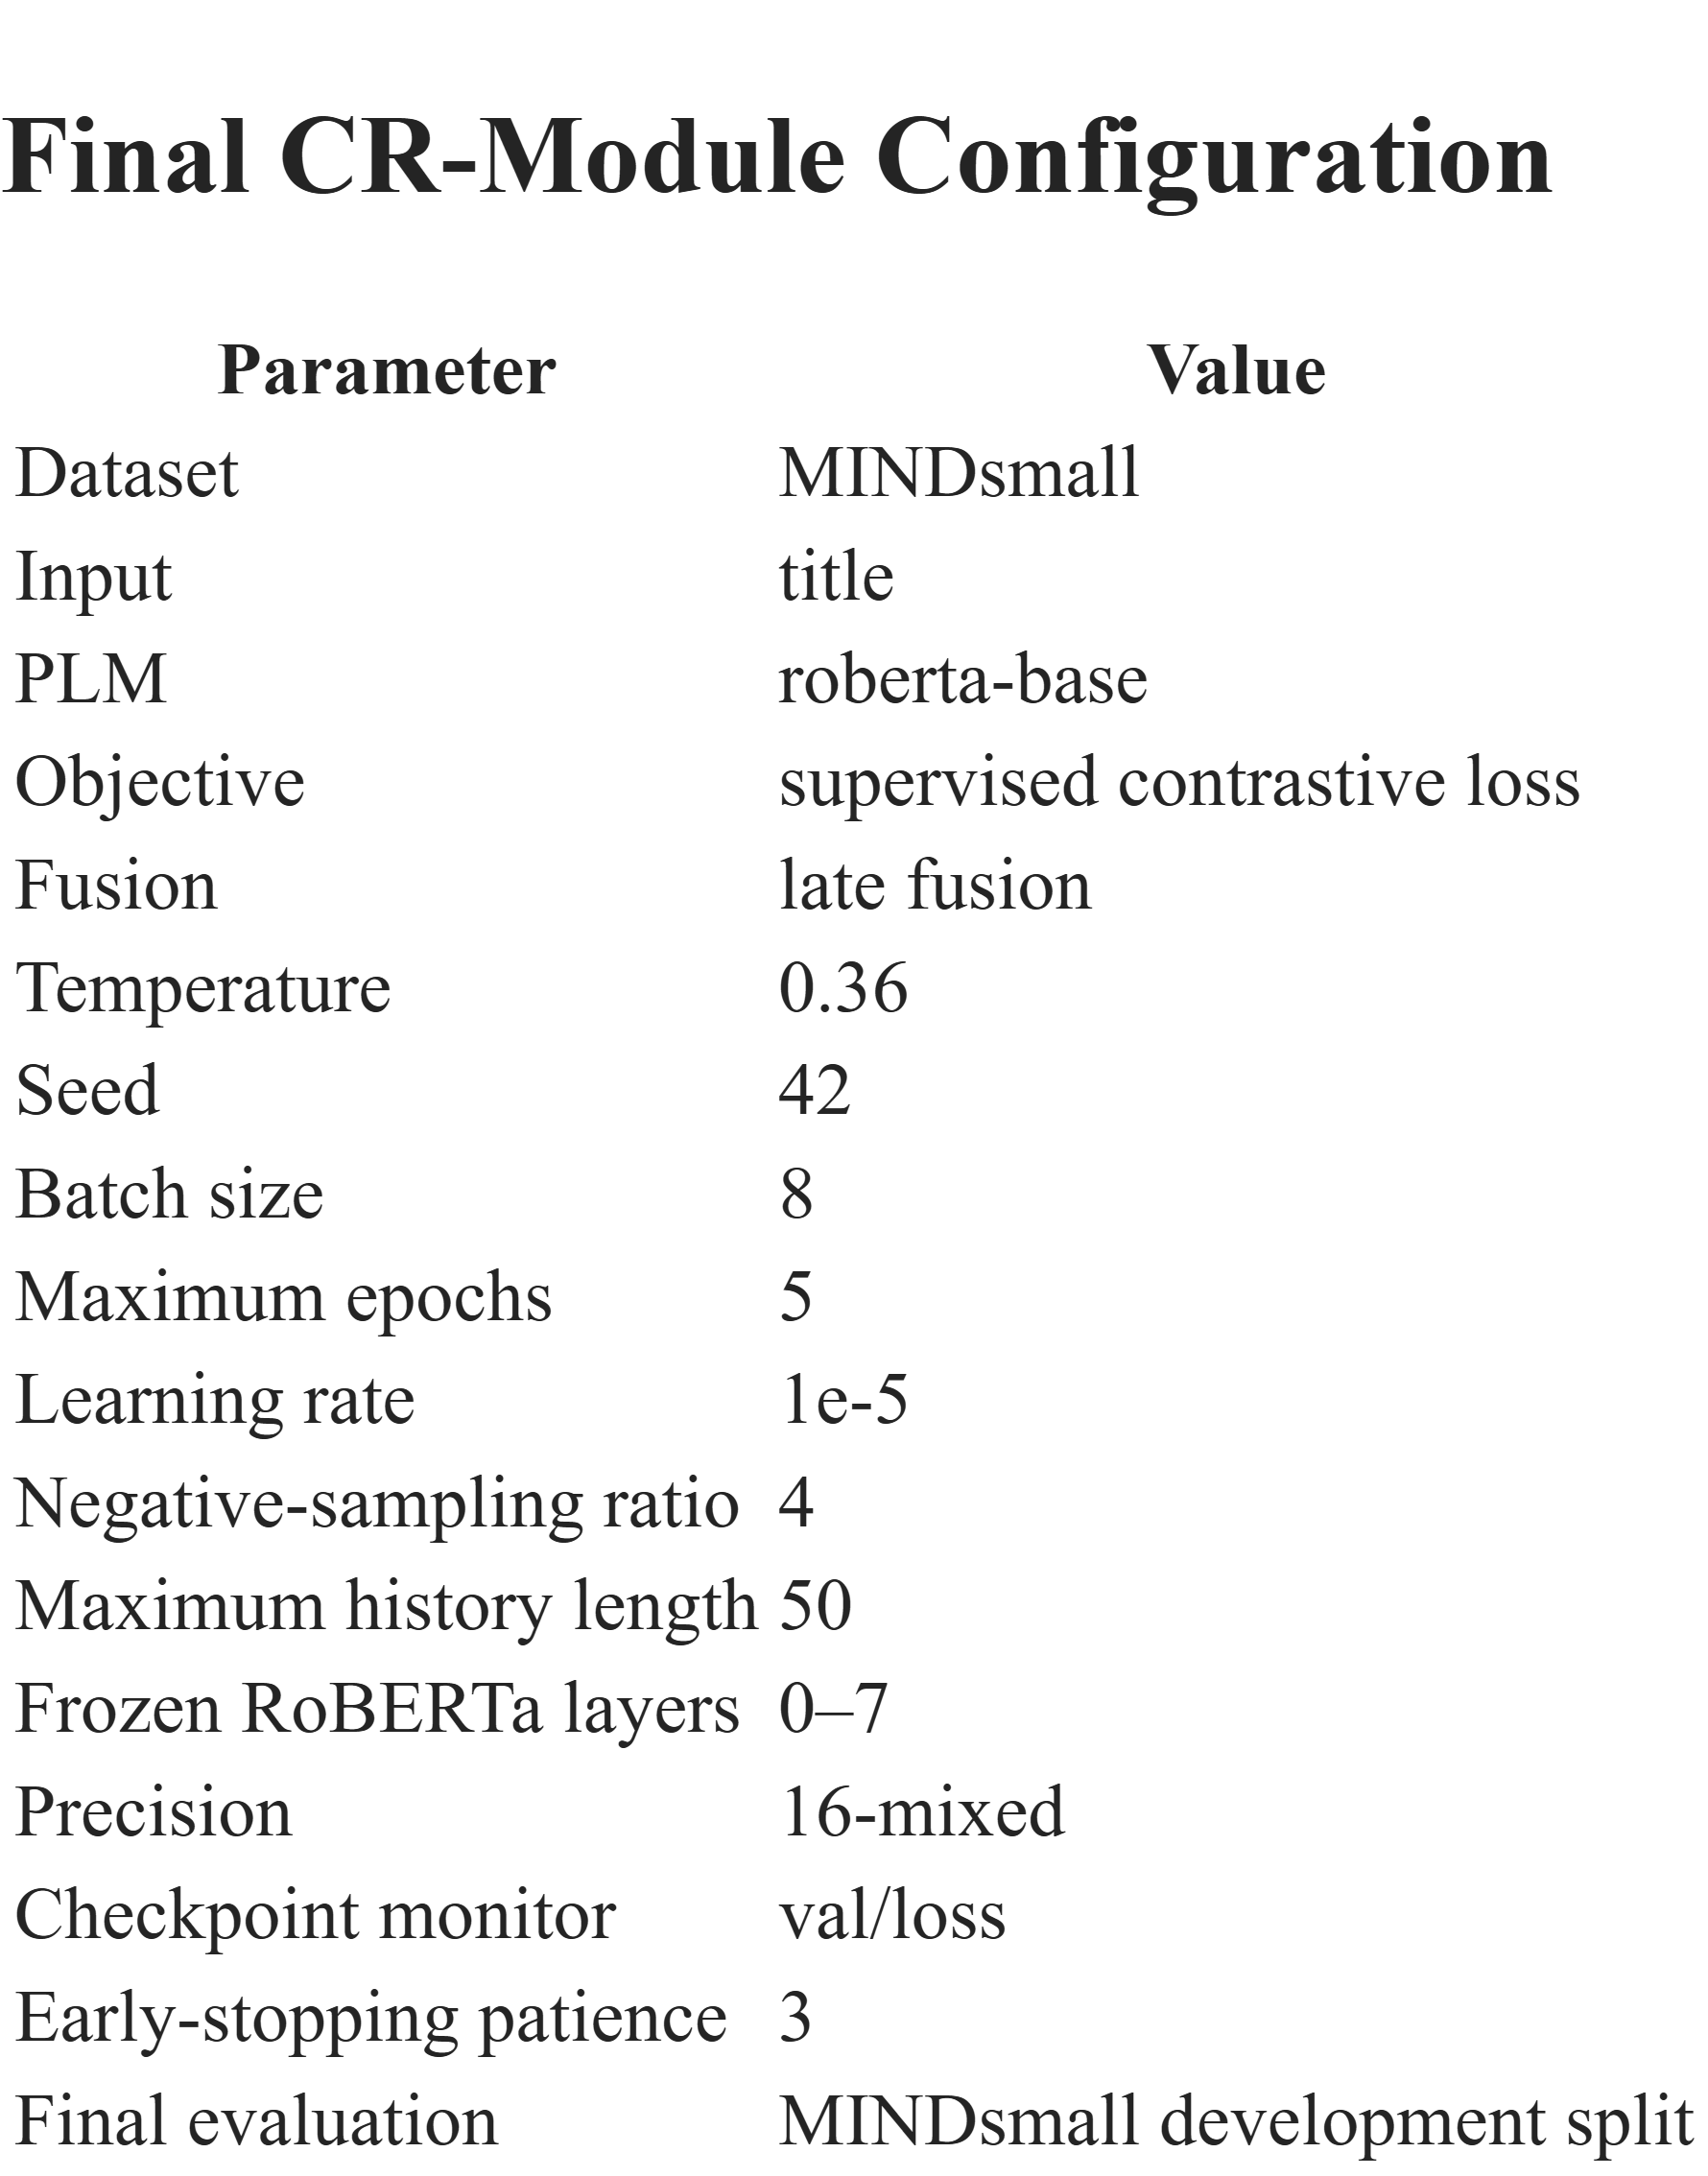

# 10. Final CR configuration validation

Rather than duplicate all the earlier configuration-building cells, load the final resolved configuration already saved in Drive:

In [ ]:
from omegaconf import OmegaConf

CR_FINAL_CONFIG = (
    CONFIG_DIR
    / "cr_final_s42_resolved.yaml"
)

if not CR_FINAL_CONFIG.exists():
    raise FileNotFoundError(
        f"Final CR configuration is missing: {CR_FINAL_CONFIG}"
    )

cr_cfg = OmegaConf.load(
    CR_FINAL_CONFIG
)

print(OmegaConf.to_yaml(cr_cfg))

task_name: train
tags:
- cr_module
- mind
- title
- scl
- lf
train: true
test: true
compile: false
ckpt_path: null
seed: 42
data:
  _target_: manner.data.mind_rec_datamodule.MINDRecDataModule
  size: small
  mind_urls:
    large:
      train: https://mind201910small.blob.core.windows.net/release/MINDlarge_train.zip
      dev: https://mind201910small.blob.core.windows.net/release/MINDlarge_dev.zip
    small:
      train: https://mind201910small.blob.core.windows.net/release/MINDsmall_train.zip
      dev: https://mind201910small.blob.core.windows.net/release/MINDsmall_dev.zip
    demo:
      train: https://recodatasets.z20.web.core.windows.net/newsrec/MINDdemo_train.zip
      dev: https://recodatasets.z20.web.core.windows.net/newsrec/MINDdemo_dev.zip
  categ_embeddings_url: https://nlp.stanford.edu/data/glove.840B.300d.zip
  data_dir: /content/drive/MyDrive/CP8339_Assignment2_MANNeR/data/
  categ_embeddings_dirname: glove
  categ_embeddings_fpath: /content/drive/MyDrive/CP8339_Assignment

Then include the assertion cell:

In [ ]:
assert cr_cfg.seed == 42
assert cr_cfg.data.size == "small"
assert list(cr_cfg.data.text_aspects) == ["title"]
assert cr_cfg.data.batch_size == 8
assert cr_cfg.data.num_workers == 0
assert cr_cfg.data.max_history_length == 50
assert cr_cfg.data.neg_sampling_ratio == 4

assert cr_cfg.model.plm_model == "roberta-base"
assert cr_cfg.model.supcon_loss is True
assert cr_cfg.model.late_fusion is True
assert cr_cfg.model.temperature == 0.36
assert cr_cfg.model.use_entities is False
assert cr_cfg.model.optimizer.lr == 1e-5

assert cr_cfg.trainer.accelerator == "gpu"
assert cr_cfg.trainer.devices == 1
assert cr_cfg.trainer.precision == "16-mixed"
assert cr_cfg.trainer.max_epochs == 5

assert cr_cfg.callbacks.model_checkpoint.monitor == "val/loss"
assert cr_cfg.callbacks.model_checkpoint.save_top_k == 1
assert cr_cfg.callbacks.model_checkpoint.save_last is True

assert cr_cfg.train is True
assert cr_cfg.test is True

for forbidden_key in [
    "limit_train_batches",
    "limit_val_batches",
    "limit_test_batches",
    "fast_dev_run",
]:
    assert forbidden_key not in cr_cfg.trainer

print("Final CR configuration validation passed.")

Final CR configuration validation passed.


# 11. Final CR execution or resume cell

We use a checkpoint-aware execution cell. This prevents accidentally restarting from zero.

In [ ]:
from pathlib import Path

CR_CHECKPOINT_DIR = (
    CHECKPOINT_DIR
    / "cr_final_s42"
)

LAST_CHECKPOINT = (
    CR_CHECKPOINT_DIR
    / "last.ckpt"
)

EPOCH_ZERO_CHECKPOINT = (
    CR_CHECKPOINT_DIR
    / "epoch_000.ckpt"
)

if LAST_CHECKPOINT.exists():
    RESUME_CHECKPOINT = LAST_CHECKPOINT
elif EPOCH_ZERO_CHECKPOINT.exists():
    RESUME_CHECKPOINT = EPOCH_ZERO_CHECKPOINT
else:
    RESUME_CHECKPOINT = None

print("Resume checkpoint:", RESUME_CHECKPOINT)

Resume checkpoint: /content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42/last.ckpt


### Validate last.ckpt before resuming

In [ ]:
from pathlib import Path
import torch

CR_CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/CP8339_Assignment2_MANNeR/"
    "checkpoints/cr_final_s42"
)

RESUME_CHECKPOINT = CR_CHECKPOINT_DIR / "last.ckpt"

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Resume checkpoint is missing: {RESUME_CHECKPOINT}"
    )

print("Resume checkpoint:")
print(RESUME_CHECKPOINT)
print(
    "File size:",
    f"{RESUME_CHECKPOINT.stat().st_size:,} bytes",
)

checkpoint_data = torch.load(
    RESUME_CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)

print("Saved epoch:", checkpoint_data.get("epoch"))
print("Saved global step:", checkpoint_data.get("global_step"))
print(
    "State-dictionary entries:",
    len(checkpoint_data.get("state_dict", {})),
)
print(
    "Optimizer states:",
    len(checkpoint_data.get("optimizer_states", [])),
)

required_keys = {
    "state_dict",
    "optimizer_states",
    "callbacks",
    "loops",
}

missing_keys = required_keys - set(checkpoint_data)

if missing_keys:
    raise RuntimeError(
        "Checkpoint is missing required resume state: "
        + ", ".join(sorted(missing_keys))
    )

if not checkpoint_data["optimizer_states"]:
    raise RuntimeError(
        "Checkpoint does not contain optimizer state."
    )

print("\nThe CR checkpoint is structurally valid for resuming.")

Resume checkpoint:
/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42/last.ckpt
File size: 1,037,563,279 bytes
Saved epoch: 0
Saved global step: 15529
State-dictionary entries: 199
Optimizer states: 1

The CR checkpoint is structurally valid for resuming.


After validation, free the CPU memory:

In [ ]:
del checkpoint_data

## While your current CR run is incomplete

Use the resume command only after GPU access returns:

In [ ]:
%cd /content/manner

!WANDB_MODE=disabled python manner/train.py \
    experiment=cr_module_mind_title_scl_lf \
    data.size=small \
    paths.data_dir=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/data/ \
    data.batch_size=8 \
    data.num_workers=0 \
    logger=csv \
    trainer.max_epochs=5 \
    trainer.profiler=null \
    callbacks.model_checkpoint.dirpath=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42 \
    hydra.run.dir=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/runs/cr_final_s42_resume \
    ckpt_path=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42/last.ckpt \
    test=True \
    2>&1 | tee /content/drive/MyDrive/CP8339_Assignment2_MANNeR/logs/cr_final_s42_resume.log

/content/manner
[2026-11-21 13:20:10,427][manner.utils.utils][INFO] - Enforcing tags! <cfg.extras.enforce_tags=True>
[2026-11-21 13:20:10,451][manner.utils.utils][INFO] - Printing config tree with Rich! <cfg.extras.print_config=True>
CONFIG
├── data
│   └── _target_: manner.data.mind_rec_datamodule.MINDRecDataModule             
│       size: small                                                             
│       mind_urls:                                                              
│         large:                                                                
│           train: https://mind201910small.blob.core.windows.net/release/MINDlar
│           dev: https://mind201910small.blob.core.windows.net/release/MINDlarge
│         small:                                                                
│           train: https://mind201910small.blob.core.windows.net/release/MINDsma
│           dev: https://mind201910small.blob.core.windows.net/release/MINDsmall
│         demo:      

If only epoch_000.ckpt exists, substitute that exact path for last.ckpt.

Once final CR training is complete, do not rerun this cell in the submitted notebook. Preserve its successful output.



---



The resume attempt failed before restoring any training state, so the checkpoint was not modified or damaged. The cause is a compatibility change between the original runtime and the new runtime:

* Original checkpoint creation: PyTorch 2.11
* Current clean runtime: PyTorch 2.14.1
* Newer PyTorch defaults torch.load() to weights_only=True
* A full Lightning checkpoint includes optimizer, callbacks, loops, and OmegaConf objects such as ListConfig, not just tensor weights

The checkpoint is trusted because it was created by your own MANNeR run and already loaded successfully with weights_only=False. PyTorch provides TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 specifically to make torch.load use weights_only=False when the caller does not explicitly select a value.

1. Do not alter or delete the checkpoints

Keep both files untouched:

```
checkpoints/cr_final_s42/last.ckpt
checkpoints/cr_final_s42/epoch_000.ckpt
```

The failed resume happened during loading, before Epoch 1 started.

2. Test the compatibility setting in isolation

In [ ]:
import os
import torch
from pathlib import Path

RESUME_CHECKPOINT = Path(
    "/content/drive/MyDrive/CP8339_Assignment2_MANNeR/"
    "checkpoints/cr_final_s42/last.ckpt"
)

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(RESUME_CHECKPOINT)

# This checkpoint is trusted because it was generated by this project.
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

checkpoint_test = torch.load(
    RESUME_CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint loaded with compatibility setting.")
print("Epoch:", checkpoint_test.get("epoch"))
print("Global step:", checkpoint_test.get("global_step"))
print(
    "Optimizer states:",
    len(checkpoint_test.get("optimizer_states", [])),
)
print(
    "State-dictionary entries:",
    len(checkpoint_test.get("state_dict", {})),
)

assert checkpoint_test.get("epoch") == 0
assert checkpoint_test.get("global_step") == 15529
assert len(checkpoint_test.get("optimizer_states", [])) == 1
assert len(checkpoint_test.get("state_dict", {})) == 199

print("Full checkpoint compatibility test passed.")

del checkpoint_test

/tmp/ipykernel_2759/873294311.py:16: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint_test = torch.load(


Checkpoint loaded with compatibility setting.
Epoch: 0
Global step: 15529
Optimizer states: 1
State-dictionary entries: 199
Full checkpoint compatibility test passed.


PyTorch warns that unrestricted pickle loading should be used only for trusted files. That condition is satisfied here because the checkpoint was generated by your own training process and stored in your own Drive.

3. Use a new resume output directory and log

The failed attempt created partial metadata under:

```
runs/cr_final_s42_resume
logs/cr_final_s42_resume.log
```
Do not mix the successful resume with that failed attempt. Use:
```
runs/cr_final_s42_resume2
logs/cr_final_s42_resume2.log
```
The checkpoint directory remains unchanged so the resumed run continues maintaining the same best and last checkpoints.

4. Run the corrected resume command

The key addition is:

```
TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
```


In [ ]:
%cd /content/manner

!WANDB_MODE=disabled \
TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 \
python manner/train.py \
    experiment=cr_module_mind_title_scl_lf \
    data.size=small \
    paths.data_dir=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/data/ \
    data.batch_size=8 \
    data.num_workers=0 \
    logger=csv \
    trainer.max_epochs=5 \
    trainer.profiler=null \
    callbacks.model_checkpoint.dirpath=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42 \
    hydra.run.dir=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/runs/cr_final_s42_resume2 \
    ckpt_path=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42/last.ckpt \
    test=True \
    2>&1 | tee /content/drive/MyDrive/CP8339_Assignment2_MANNeR/logs/cr_final_s42_resume2.log

/content/manner
[2026-11-21 13:35:34,727][manner.utils.utils][INFO] - Enforcing tags! <cfg.extras.enforce_tags=True>
[2026-11-21 13:35:34,755][manner.utils.utils][INFO] - Printing config tree with Rich! <cfg.extras.print_config=True>
CONFIG
├── data
│   └── _target_: manner.data.mind_rec_datamodule.MINDRecDataModule             
│       size: small                                                             
│       mind_urls:                                                              
│         large:                                                                
│           train: https://mind201910small.blob.core.windows.net/release/MINDlar
│           dev: https://mind201910small.blob.core.windows.net/release/MINDlarge
│         small:                                                                
│           train: https://mind201910small.blob.core.windows.net/release/MINDsma
│           dev: https://mind201910small.blob.core.windows.net/release/MINDsmall
│         demo:      



---



# 12. Results and artifact verification

The clean notebook should finish with cells that:

1. list the final checkpoints;
2. load and validate the selected checkpoint;
3. display metrics.csv;
4. extract final test metrics;
5. summarize the result.

Example checkpoint listing:

In [ ]:
CR_CHECKPOINT_DIR = (
    CHECKPOINT_DIR
    / "cr_final_s42"
)

cr_checkpoints = sorted(
    CR_CHECKPOINT_DIR.glob("*.ckpt")
)

print("Final CR checkpoints:", len(cr_checkpoints))

for checkpoint in cr_checkpoints:
    print(
        checkpoint.name,
        f"{checkpoint.stat().st_size:,} bytes",
    )

Display metrics:

In [ ]:
import pandas as pd

CR_RUN_ROOT = RUNS_DIR

cr_metric_files = sorted(
    CR_RUN_ROOT.rglob("metrics.csv")
)

for path in cr_metric_files:
    if "cr_final_s42" in str(path):
        print(path)

Once training finishes, select the correct final metrics file and display it.

### Final folder arrangement:



```
My Drive/
├── Colab Notebooks/
│   ├── MANNeR_Development_Working.ipynb
│   └── MANNeR_Final_Submission.ipynb
│
└── CP8339_Assignment2_MANNeR/
    ├── checkpoints/
    ├── code_changes/
    ├── configs_used/
    ├── data/
    ├── environment/
    ├── logs/
    ├── results/
    └── runs/
```



### Runtime-continuation note

The initial full CR epoch was completed in a Colab runtime using PyTorch 2.11.0. After the free Colab runtime disconnected, training was resumed from the complete Lightning last.ckpt under PyTorch 2.14.1. The checkpoint restored the model, optimizer, callbacks, loop state, completed epoch 0, and global step 15,529. The model configuration, dataset, seed, and hyperparameters were unchanged.

# After session disconnection: Before resuming training, inspect progress

In [7]:
import os
import torch
from pathlib import Path

os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

CR_CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/CP8339_Assignment2_MANNeR/"
    "checkpoints/cr_final_s42"
)

LAST_CHECKPOINT = CR_CHECKPOINT_DIR / "last.ckpt"

checkpoint_state = torch.load(
    LAST_CHECKPOINT,
    map_location="cpu",
)

print("Saved epoch:", checkpoint_state.get("epoch"))
print("Saved global step:", checkpoint_state.get("global_step"))
print(
    "Optimizer states:",
    len(checkpoint_state.get("optimizer_states", [])),
)

del checkpoint_state

/tmp/ipykernel_2177/3946055999.py:14: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint_state = torch.load(


Saved epoch: 0
Saved global step: 15529
Optimizer states: 1


Then run this short preflight:

In [12]:
from pathlib import Path

REPO_DIR = Path("/content/manner")

cr_source = (
    REPO_DIR / "manner/models/cr_module.py"
).read_text(encoding="utf-8")

assert (REPO_DIR / ".project-root").exists()
assert "RetrievalNormalizedDCG(k=" not in cr_source
assert "RetrievalNormalizedDCG(top_k=5)" in cr_source
assert "RetrievalNormalizedDCG(top_k=10)" in cr_source

print("CR resume preflight passed.")

CR resume preflight passed.


Did the steps up to (not icluding) 9

# Run these before resuming

## 1. Validate last.ckpt again

In [13]:
import os
import torch
from pathlib import Path

os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

LAST_CHECKPOINT = Path(
    "/content/drive/MyDrive/CP8339_Assignment2_MANNeR/"
    "checkpoints/cr_final_s42/last.ckpt"
)

if not LAST_CHECKPOINT.is_file():
    raise FileNotFoundError(LAST_CHECKPOINT)

checkpoint_state = torch.load(
    LAST_CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint:", LAST_CHECKPOINT)
print("Saved epoch:", checkpoint_state.get("epoch"))
print("Saved global step:", checkpoint_state.get("global_step"))
print(
    "State-dictionary entries:",
    len(checkpoint_state.get("state_dict", {})),
)
print(
    "Optimizer states:",
    len(checkpoint_state.get("optimizer_states", [])),
)

assert checkpoint_state.get("epoch") == 0
assert checkpoint_state.get("global_step") == 15529
assert len(checkpoint_state.get("state_dict", {})) == 199
assert len(checkpoint_state.get("optimizer_states", [])) == 1

print("\nCR checkpoint is valid for resuming.")

/tmp/ipykernel_2177/2348289302.py:15: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint_state = torch.load(


Checkpoint: /content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42/last.ckpt
Saved epoch: 0
Saved global step: 15529
State-dictionary entries: 199
Optimizer states: 1

CR checkpoint is valid for resuming.


## 2. Free CPU memory

In [14]:
del checkpoint_state

import gc
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Checkpoint inspection memory released.")

Checkpoint inspection memory released.


# Resume with a new run directory and log

In [ ]:
%cd /content/manner

!WANDB_MODE=disabled \
TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 \
python manner/train.py \
    experiment=cr_module_mind_title_scl_lf \
    data.size=small \
    paths.data_dir=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/data/ \
    data.batch_size=8 \
    data.num_workers=0 \
    logger=csv \
    trainer.max_epochs=5 \
    trainer.profiler=null \
    callbacks.model_checkpoint.dirpath=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42 \
    hydra.run.dir=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/runs/cr_final_s42_resume3 \
    ckpt_path=/content/drive/MyDrive/CP8339_Assignment2_MANNeR/checkpoints/cr_final_s42/last.ckpt \
    test=True \
    2>&1 | tee /content/drive/MyDrive/CP8339_Assignment2_MANNeR/logs/cr_final_s42_resume3.log

/content/manner
[2026-11-22 16:29:12,165][manner.utils.utils][INFO] - Enforcing tags! <cfg.extras.enforce_tags=True>
[2026-11-22 16:29:12,177][manner.utils.utils][INFO] - Printing config tree with Rich! <cfg.extras.print_config=True>
CONFIG
├── data
│   └── _target_: manner.data.mind_rec_datamodule.MINDRecDataModule             
│       size: small                                                             
│       mind_urls:                                                              
│         large:                                                                
│           train: https://mind201910small.blob.core.windows.net/release/MINDlar
│           dev: https://mind201910small.blob.core.windows.net/release/MINDlarge
│         small:                                                                
│           train: https://mind201910small.blob.core.windows.net/release/MINDsma
│           dev: https://mind201910small.blob.core.windows.net/release/MINDsmall
│         demo:      